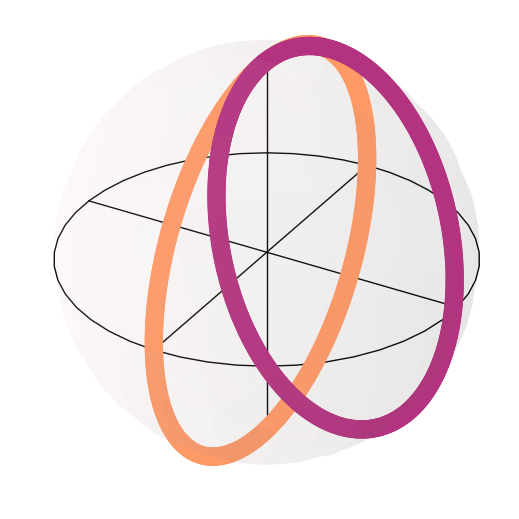

In [8]:
from qutip import Bloch
import numpy as np
import matplotlib.pyplot as plt

def bloch_vector(t, Omega, Delta):
    Omega_eff = np.sqrt(Omega**2 + Delta**2)
    y = (Omega * Delta / Omega_eff**2) * (1 - np.cos(Omega_eff * t))
    x = (Omega / Omega_eff) * np.sin(Omega_eff * t)
    z = 1 - (Omega**2 / Omega_eff**2) * (1 - np.cos(Omega_eff * t))
    return x, y, z

# Define Colors
color0 = [1,0.6,0.4] # RGB color for the first trace
color1 = [0.7,0.2,0.5] # RGB color for the second trace
# Create a Bloch sphere
b = Bloch()
b.point_marker = 'o'  # Set the marker style for points
b.point_size = [150,150]  # Set the size of the points
b.xlabel = ['','']  # Set the labels for the x-axis
b.ylabel = ['','']  # Set the labels for the y-axis
b.zlabel = ['','']  # Set the labels for the z-axis
b.sphere_alpha = 0.07  # Set the transparency of the sphere
b.frame_alpha = 0.1  # Set the transparency of the frame
b.font_size = 40  # Set the font size for labels
b.frame_color = 'black'  # Remove the frame color for a simpler look
b.frame_alpha = 0.0   # Make the frame fully transparent
# Add a trace along a circular path from the north pole to the equatorial plane and back
tau0=np.linspace(0, 2*np.pi, 500)
tau1=np.linspace(0, 2*np.pi, 500)
Omega = 1.0
[x0,y0,z0]=bloch_vector(tau0, Omega, 0.0)
[x1,y1,z1]=bloch_vector(tau1, Omega, 0.5)
b.add_points([x0, y0, z0], 'm', color0)
b.add_points([x1, y1, z1], 'm', color1)
b.show()
b.save('P:/Papers/E-Field and Dimers/Figure4/VectorGraphics/bloch_sphere.svg')
# Optional: Save the Bloch sphere as an image
# b.save('bloch_sphere.png')

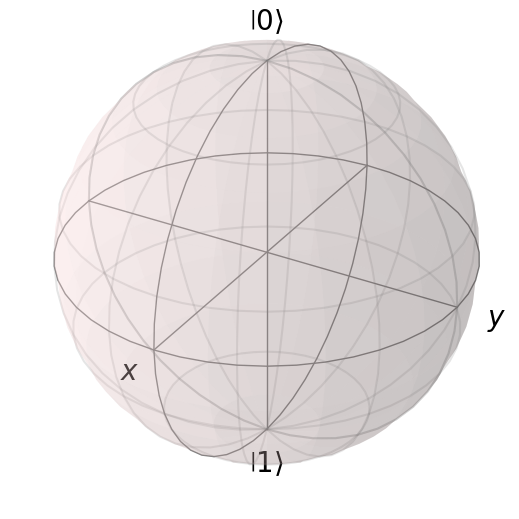

In [3]:
from qutip import Qobj, Bloch, tensor, basis

# Define the two-qubit state (e.g., Bell state |ψ⟩ = (|00⟩ + |11⟩) / √2)
bell_state = (tensor(basis(2, 0), basis(2, 0)) + tensor(basis(2, 1), basis(2, 1))).unit()

# Compute the reduced density matrix for the first qubit
rho = bell_state.ptrace(0)

# Extract the Bloch vector components
bloch_vector = [rho.tr() for rho in [Qobj([[0, 1], [1, 0]]), Qobj([[0, -1j], [1j, 0]]), Qobj([[1, 0], [0, -1]])]]

# Plot the Bloch sphere
b = Bloch()
b.add_vectors(bloch_vector)
b.show()